# Trees as points and counts

Some objects are best recorded as a location. This notebook follows tree positions through targets,
decoding and GeoJSON, using two heads that answer different questions. The heatmap head says where
each tree is, and the density head says how many there are in an area. Then it shows why the
threshold on the heatmap is a choice you have to make from data.

As in the [footprints notebook](03_vector_footprints.ipynb), **no trained model appears here**.
The trees are synthetic and the scene's targets stand in for a trained model's outputs. It runs on a
CPU in under a minute with nothing to download.

Vector outputs are experimental, so names and defaults may change before 1.0. You need
`pip install "manyseg[vectors]" matplotlib`.

In [1]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import shapely
import torch
from manyseg import create_model
from manyseg.points import density_head, density_map, gaussian_heatmap, point_heads, points_from_xy
from manyseg.vectors import Scene, block_decoder, decode_scene, to_pixels
from scipy.ndimage import gaussian_filter
from scipy.optimize import linear_sum_assignment

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})
BLUE, ORANGE = "#1f6fb4", "#d9480f"

## Tree positions in a real coordinate system

The scene is 400 x 400 px at 0.5 m in MGA zone 50, with 60 trees at least 4 m apart. One thing to
watch is that `manyseg.points` works in `(y, x)` with pixel centres at integers, while GIS and
`manyseg.vectors` work in `(x, y)` with pixel corners at integers. `points_from_xy` converts between
them, and it's the only conversion you need going in.

In [2]:
TRANSFORM = (0.5, 0.0, 391_000.0, 0.0, -0.5, 6_466_000.0)
CRS = "EPSG:28350"
SHAPE = (400, 400)


def make_trees(n=60):
    rng = np.random.default_rng(0)
    points = []
    while len(points) < n:
        p = rng.uniform((391_002, 6_465_802), (391_198, 6_465_998))
        if all(np.hypot(*(p - q)) >= 4 for q in points):
            points.append(p)
    return [shapely.Point(p) for p in points]


trees = make_trees()
xy = to_pixels(trees, TRANSFORM, SHAPE, crs=CRS, raster_crs=CRS, kind="points")
yx = points_from_xy(xy)
print(f"{len(xy)} trees in the scene")

60 trees in the scene


## Two targets from the same points

Each tree becomes a Gaussian in both maps. The heatmap's peaks reach about 1, which suits finding
them. The density map is scaled so the scene sums to the number of trees. Adding up a smaller area
gives its approximate count, because a tree near the area's edge spills across it.

heatmap peak 1.00; density sums to 60.00


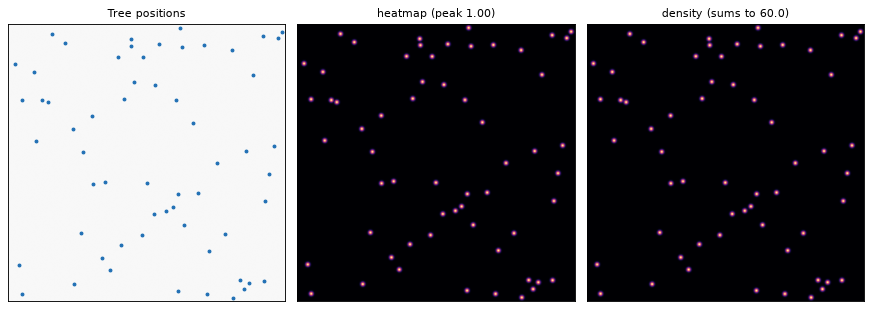

In [3]:
heatmap = gaussian_heatmap([yx], SHAPE, sigma=2.0)[0].numpy()
density = density_map([yx], SHAPE, sigma=2.0)[0].numpy()
print(f"heatmap peak {heatmap.max():.2f}; density sums to {density.sum():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(np.full(SHAPE, 0.97), cmap="gray", vmin=0, vmax=1)
axes[0].plot(*xy.T, ".", c=BLUE, ms=5)
axes[0].set_title("Tree positions")
axes[1].imshow(heatmap[0], cmap="magma")
axes[1].set_title(f"heatmap (peak {heatmap.max():.2f})")
axes[2].imshow(density[0], cmap="magma")
axes[2].set_title(f"density (sums to {density.sum():.1f})")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## The model

We build it only to check its output shapes. Both heads return plain values, so there are no
sigmoids. The heatmap trains with MSE, and the density head has a softplus output, so it can't go
negative.

In [4]:
model = create_model(backbone="resnet18", pretrained=False, in_channels=3,
                     heads={**point_heads(), **density_head(activation="softplus")}).eval()
with torch.no_grad():
    out = model(torch.rand(1, 3, 128, 128))
print({head: tuple(v.shape) for head, v in out.items()})

fields = {"heatmap": heatmap, "density": density}  # a trained model's stitched scene goes here

{'heatmap': (1, 1, 128, 128), 'density': (1, 1, 128, 128)}


## Decode block by block

Points get a peak finder, and each peak belongs to the block whose core contains its pixel. Density
gets summed per block. Peaks land on whole pixels, so they can sit up to about 0.7 px from the
true position. An offset head would give sub-pixel positions.

60 peaks, furthest 0.68 px from a tree
density count 60.00 over 16 blocks


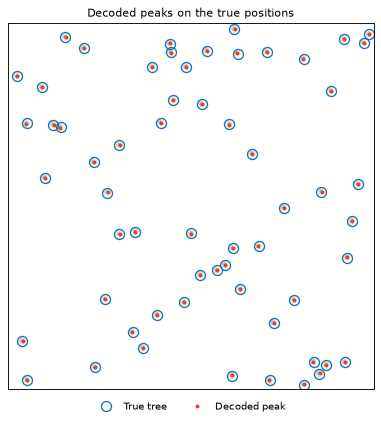

In [5]:
scene = Scene(*SHAPE, transform=TRANSFORM, crs=CRS)
decoded = decode_scene(fields, block_decoder("points", threshold=0.5, kernel=3), block=128, halo=16,
                       scene=scene)
count = decode_scene(fields, block_decoder("density"), block=128, halo=0, scene=scene)
distance = np.hypot(*(decoded.xy[:, None] - xy[None]).transpose(2, 0, 1)).min(1)
print(f"{len(decoded)} peaks, furthest {distance.max():.2f} px from a tree")
print(f"density count {count.total:.2f} over {len(count.counts)} blocks")

fig, ax = plt.subplots(figsize=(5.4, 5.4))
ax.imshow(heatmap[0], cmap="gray_r", vmin=0, vmax=3)
ax.plot(*xy.T, "o", mfc="none", mec=BLUE, ms=9, mew=1.2, label="True tree")
ax.plot(*decoded.xy.T, ".", c=ORANGE, ms=5, label="Decoded peak")
ax.legend(frameon=False, loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.01), fontsize=9)
ax.set(title="Decoded peaks on the true positions", xticks=[], yticks=[])
fig.tight_layout()

## Choosing a threshold

Perfect targets peak at about 1, and a threshold of 0.5 finds every tree. Real heatmaps trained with MSE
rarely reach 1, and a fixed 0.5 cost recall in
[E011b](https://github.com/DPIRD-DMA/ManySeg/tree/main/experiments/E011b_point_threshold_calibration), where a threshold chosen on
validation data raised test F1 from 0.40 to 0.59. To show why, we shrink and blur the heatmap, add
noise, and sweep the threshold. A peak counts as correct within 3 px of a tree, and each tree
matches at most one peak.

This is a rough stand-in for a real model. The shape of the curves is the point. The best threshold
on your model will differ, so choose it on your own validation set.

weakened heatmap peak 0.43
at threshold 0.50: precision 1.00, recall 0.00, F1 0.00
at threshold 0.30: precision 0.91, recall 1.00, F1 0.95


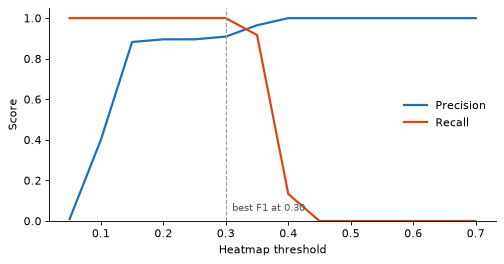

In [6]:
def weaken(heatmap, scale=0.45, blur=1.0, noise=0.03, seed=0):
    rng = np.random.default_rng(seed)
    soft = gaussian_filter(heatmap, (0, blur, blur)) * scale
    return soft + rng.normal(0, noise, soft.shape).astype(np.float32)


def precision_recall(points, truth, tolerance=3.0):
    if not len(points):
        return 1.0, 0.0
    distances = np.hypot(*(points[:, None] - truth[None]).transpose(2, 0, 1))
    # pairs beyond the tolerance cost more than any set of valid pairs, so the most pairs match
    far = distances > tolerance
    rows, columns = linear_sum_assignment(np.where(far, tolerance * (len(points) + 1), distances))
    matched = (~far[rows, columns]).sum()
    return matched / len(points), matched / len(truth)


weak = {"heatmap": weaken(heatmap), "density": density}
thresholds = np.arange(0.05, 0.71, 0.05)
curve = []
for threshold in thresholds:
    decoder = block_decoder("points", threshold=float(threshold), kernel=3)
    points = decode_scene(weak, decoder, block=128, halo=16, scene=scene)
    curve.append(precision_recall(points.xy, xy))
precision, recall = np.array(curve).T
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)
best = thresholds[f1.argmax()]
print(f"weakened heatmap peak {weak['heatmap'].max():.2f}")
print(f"at threshold 0.50: precision {precision[9]:.2f}, recall {recall[9]:.2f}, F1 {f1[9]:.2f}")
print(f"at threshold {best:.2f}: precision {precision[f1.argmax()]:.2f}, "
      f"recall {recall[f1.argmax()]:.2f}, F1 {f1.max():.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(thresholds, precision, c=BLUE, lw=2, label="Precision")
ax.plot(thresholds, recall, c=ORANGE, lw=2, label="Recall")
ax.axvline(best, c="#999999", lw=1, ls="--")
ax.text(best + 0.01, 0.05, f"best F1 at {best:.2f}", fontsize=9, color="#555555")
ax.set(xlabel="Heatmap threshold", ylabel="Score", ylim=(0, 1.05))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="center right")
fig.tight_layout()

## Counts don't need a threshold

Density needs no threshold, because you add it up, which makes it a useful check on the point
count. It has its own weakness, though. A softplus head can't go negative, so small errors over
empty ground only ever add to the total. We imitate that below with noise clipped at 0. The density
map's peaks are only about 0.04, so even small values matter over 160,000 pixels. Check a density
head's count on empty areas too.

In [7]:
rng = np.random.default_rng(0)
for noise in (0.0, 0.0002, 0.001, 0.002):
    noisy = np.clip(density + rng.normal(0, noise, density.shape).astype(np.float32), 0, None)
    total = decode_scene({"density": noisy}, block_decoder("density"), block=128, halo=0,
                         scene=scene).total
    print(f"density noise {noise}: count {total:.1f} (true {len(xy)})")

density noise 0.0: count 60.0 (true 60)
density noise 0.0002: count 72.1 (true 60)
density noise 0.001: count 121.3 (true 60)
density noise 0.002: count 183.4 (true 60)


## Write GeoJSON

`to_geojson` goes through the scene's transform and names its CRS, and each point keeps its score.

In [8]:
collection = decoded.to_geojson()
with TemporaryDirectory() as tmp:
    path = Path(tmp) / "trees.geojson"
    path.write_text(json.dumps(collection))
    print(f"{len(json.loads(path.read_text())['features'])} points")
feature = collection["features"][0]
print("first tree:", feature["geometry"]["coordinates"], feature["properties"])

60 points
first tree: [391019.75, 6465915.75] {'score': 0.999281644821167}


## Where to go next

* Train the heads briefly with
  [`examples/point_counting.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/point_counting.py).
* See the other vector outputs: [footprints](03_vector_footprints.ipynb),
  [fields](04_vector_fields.ipynb), [roads](05_vector_roads.ipynb) and
  [roofs](06_vector_roofs.ipynb).